# ENG5338 CW2 — Virtual CO sensor (UCI Air Quality)

## Part A — M1: data, question, constraints, shared protocol and linear reference
Sections below (data → features → split/CV → scorers → harness → LR/Ridge) are the **frozen shared protocol**. Do not edit without telling M1.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
from pathlib import Path
# Works from the repo root, from notebooks/, or in Colab after cloning the repo
DATA_PATH = next(p for p in [Path("data/air-quality.csv"), Path("../data/air-quality.csv"),
                             Path("eng5338-cw2-air-quality/data/air-quality.csv")] if p.exists())
df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)
print(df.shape)
print(df["datetime"].min(), "->", df["datetime"].max())
df.head()

(9357, 14)
2004-03-10 18:00:00 -> 2005-04-04 14:00:00


,datetime,co_gt,pt08_s1_co,nmhc_gt,c6h6_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity_pct,absolute_humidity
0,2004-03-10 18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,2004-03-10 19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,2004-03-10 20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,2004-03-10 21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,2004-03-10 22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [3]:
print("NaN before:", df.isna().sum().sum())
df = df.replace(-200, np.nan)

missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
missing.sort_values("pct", ascending=False)

NaN before: 0


,missing,pct
nmhc_gt,8443,90.2
co_gt,1683,18.0
no2_gt,1642,17.5
nox_gt,1639,17.5
c6h6_gt,366,3.9
pt08_s1_co,366,3.9
pt08_s5_o3,366,3.9
pt08_s2_nmhc,366,3.9
pt08_s3_nox,366,3.9
pt08_s4_no2,366,3.9


In [4]:
df = df.drop(columns=["nmhc_gt"])
df = df.dropna(subset=["co_gt"]).reset_index(drop=True)
print(len(df), "rows remain")

7674 rows remain


In [5]:
SENSOR_COLS  = ["pt08_s1_co", "pt08_s2_nmhc", "pt08_s3_nox", "pt08_s4_no2", "pt08_s5_o3"]
WEATHER_COLS = ["temperature_c", "relative_humidity_pct", "absolute_humidity"]
TARGET = "co_gt"

df[[TARGET] + SENSOR_COLS + WEATHER_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
co_gt,7674.0,2.15,1.45,0.10,1.10,1.80,2.90,11.90
pt08_s1_co,7344.0,1110.58,218.68,647.00,946.00,1075.00,1246.00,2040.00
pt08_s2_nmhc,7344.0,947.20,265.47,387.00,743.00,919.00,1125.25,2214.00
pt08_s3_nox,7344.0,826.92,256.65,322.00,649.00,795.00,960.00,2683.00
pt08_s4_no2,7344.0,1444.75,350.34,551.00,1203.00,1447.00,1673.00,2775.00
pt08_s5_o3,7344.0,1043.51,405.57,221.00,744.75,990.00,1305.00,2523.00
temperature_c,7344.0,17.77,8.86,-1.90,11.20,16.90,23.80,44.60
relative_humidity_pct,7344.0,49.06,17.45,9.20,35.40,49.30,62.50,88.70
absolute_humidity,7344.0,0.99,0.40,0.18,0.70,0.96,1.26,2.18


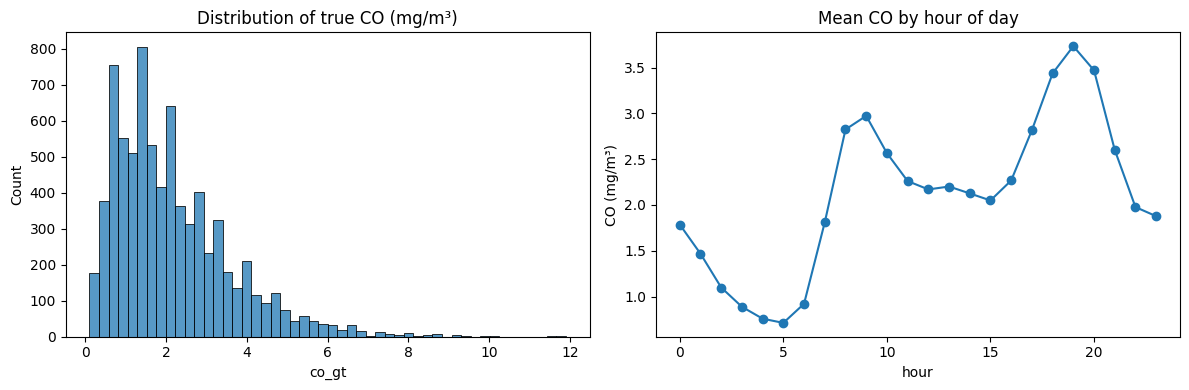

In [6]:
df["hour"] = df["datetime"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0])
ax[0].set_title("Distribution of true CO (mg/m³)")

df.groupby("hour")[TARGET].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("Mean CO by hour of day")
ax[1].set_ylabel("CO (mg/m³)")
plt.tight_layout(); plt.show()

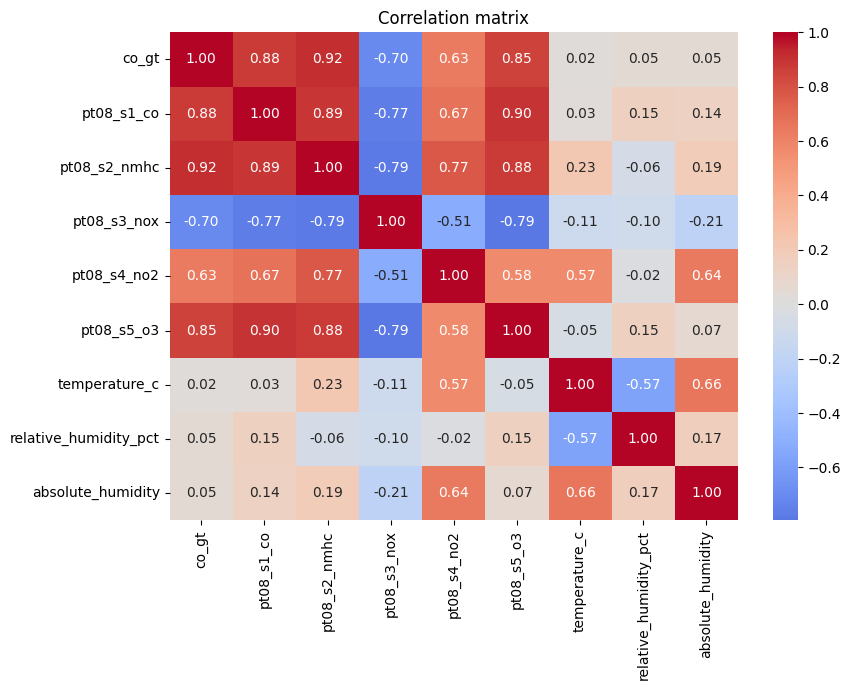

,co_gt
pt08_s2_nmhc,0.915514
pt08_s1_co,0.879288
pt08_s5_o3,0.854182
pt08_s4_no2,0.630703
relative_humidity_pct,0.048890
absolute_humidity,0.048556
temperature_c,0.022109
pt08_s3_nox,-0.703446


In [7]:
corr = df[[TARGET] + SENSOR_COLS + WEATHER_COLS].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

corr[TARGET].drop(TARGET).sort_values(ascending=False)

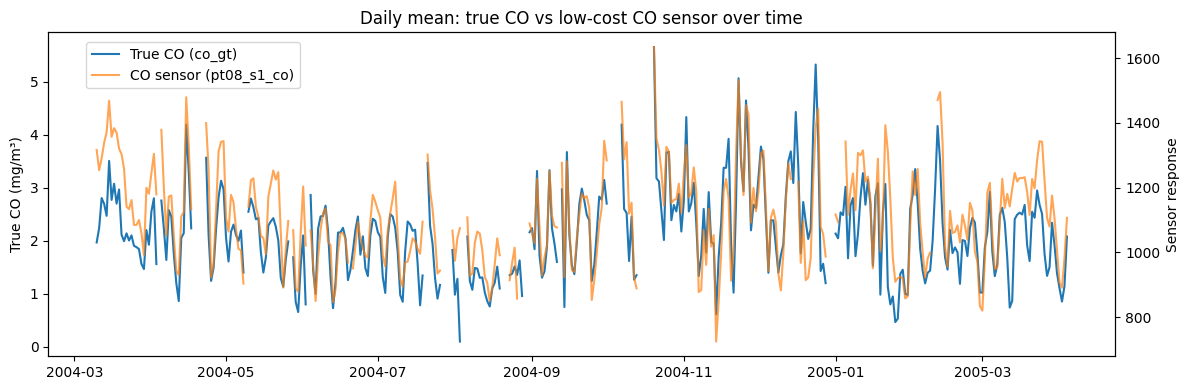

In [8]:
daily = df.set_index("datetime")[[TARGET, "pt08_s1_co"]].resample("D").mean()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(daily.index, daily[TARGET], label="True CO (co_gt)", color="tab:blue")
ax1.set_ylabel("True CO (mg/m³)")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["pt08_s1_co"], label="CO sensor (pt08_s1_co)", color="tab:orange", alpha=0.7)
ax2.set_ylabel("Sensor response")
ax1.set_title("Daily mean: true CO vs low-cost CO sensor over time")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.tight_layout(); plt.show()

In [9]:
df["hour"] = df["datetime"].dt.hour            # 0 to 23
df["weekday"] = df["datetime"].dt.weekday      # 0 = Monday ... 6 = Sunday
df["is_weekend"] = (df["weekday"] >= 5).astype(int)   # 1 if Sat/Sun, else 0

In [10]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

In [11]:
SENSOR_COLS  = ["pt08_s1_co", "pt08_s2_nmhc", "pt08_s3_nox", "pt08_s4_no2", "pt08_s5_o3"]
WEATHER_COLS = ["temperature_c", "relative_humidity_pct", "absolute_humidity"]
TIME_COLS    = ["hour_sin", "hour_cos", "weekday", "is_weekend"]

FEATURES = SENSOR_COLS + WEATHER_COLS + TIME_COLS
TARGET = "co_gt"

print(len(FEATURES), "features:", FEATURES)

12 features: ['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3', 'temperature_c', 'relative_humidity_pct', 'absolute_humidity', 'hour_sin', 'hour_cos', 'weekday', 'is_weekend']


In [12]:
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df  = df.iloc[split_idx:]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print(f"Train: {len(train_df)} rows  {train_df.datetime.min():%Y-%m-%d} -> {train_df.datetime.max():%Y-%m-%d}")
print(f"Test : {len(test_df)} rows  {test_df.datetime.min():%Y-%m-%d} -> {test_df.datetime.max():%Y-%m-%d}")

Train: 6139 rows  2004-03-10 -> 2005-01-29
Test : 1535 rows  2005-01-29 -> 2005-04-04


In [13]:
from sklearn.model_selection import TimeSeriesSplit

CV = TimeSeriesSplit(n_splits=5)
for i, (tr, va) in enumerate(CV.split(X_train)):
    print(f"Fold {i+1}: train {len(tr):5d} rows | validate {len(va):4d} rows "
          f"({train_df.datetime.iloc[va[0]]:%Y-%m-%d} -> {train_df.datetime.iloc[va[-1]]:%Y-%m-%d})")

Fold 1: train  1024 rows | validate 1023 rows (2004-05-02 -> 2004-06-23)
Fold 2: train  2047 rows | validate 1023 rows (2004-06-23 -> 2004-08-16)
Fold 3: train  3070 rows | validate 1023 rows (2004-08-16 -> 2004-10-27)
Fold 4: train  4093 rows | validate 1023 rows (2004-10-27 -> 2004-12-10)
Fold 5: train  5116 rows | validate 1023 rows (2004-12-10 -> 2005-01-29)


In [14]:
from sklearn.metrics import make_scorer

TOLERANCE = 0.5          # mg/m³ – constraint 1
TARGET_PCT = 90          # %     – constraint 1
LATENCY_LIMIT_MS = 1.0   # ms per sample – constraint 2

def pct_within(y_true, y_pred, tol=TOLERANCE):
    return 100 * np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= tol)

SCORING = {
    "mae":    "neg_mean_absolute_error",
    "rmse":   "neg_root_mean_squared_error",
    "r2":     "r2",
    "within": make_scorer(pct_within),
}
PRIMARY = "mae"

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def make_preprocessor(scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(steps), FEATURES)])

In [16]:
from sklearn.model_selection import GridSearchCV
import platform, os

RUNTIME = f"{platform.processor() or platform.machine()} | {os.cpu_count()} CPU cores | Python {platform.python_version()}"
print("Runtime:", RUNTIME)

results = []   # every model adds one row here

def evaluate_search(name, gs):
    r, i = gs.cv_results_, gs.best_index_
    row = {
        "model": name,
        "train_MAE": -r["mean_train_mae"][i],
        "val_MAE":   -r["mean_test_mae"][i],
        "val_MAE_std": r["std_test_mae"][i],
        "train_R2": r["mean_train_r2"][i],
        "val_R2":   r["mean_test_r2"][i],
        "train_within_%": r["mean_train_within"][i],
        "val_within_%":   r["mean_test_within"][i],
        "mean_fit_time_s": r["mean_fit_time"][i],
        "best_params": gs.best_params_,
    }
    row["overfit_gap_MAE"] = row["val_MAE"] - row["train_MAE"]
    results.append(row)
    return pd.Series(row)

def run_search(name, pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit=PRIMARY,
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs, evaluate_search(name, gs)

Runtime: x86_64 | 2 CPU cores | Python 3.13.18


In [17]:
from sklearn.linear_model import LinearRegression
lin_pipe = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
lin_gs, lin_res = run_search("Linear Regression", lin_pipe, {})
lin_res


,0
model,Linear Regression
train_MAE,0.254667
val_MAE,0.450405
val_MAE_std,0.120358
train_R2,0.927522
val_R2,0.788732
train_within_%,88.006838
val_within_%,68.5826
mean_fit_time_s,0.046737
best_params,{}


In [18]:
from sklearn.linear_model import Ridge
ridge_pipe = Pipeline([("prep", make_preprocessor()), ("model", Ridge())])
ridge_grid = {"model__alpha": np.logspace(-3, 3, 13)}
ridge_gs, ridge_res = run_search("Ridge (baseline)", ridge_pipe, ridge_grid)
ridge_res

,0
model,Ridge (baseline)
train_MAE,0.282868
val_MAE,0.430359
val_MAE_std,0.150591
train_R2,0.912831
val_R2,0.806051
train_within_%,84.966868
val_within_%,72.57087
mean_fit_time_s,0.018092
best_params,{'model__alpha': 316.22776601683796}


## Part B — M2: Random Forest


## Part C — M3: HistGradientBoosting


## Part D — M4: SVR / KNN


## Part E — M1: overfitting analysis (learning curves, per-fold scores over time)


## Part F — M5: computational cost (n_jobs=1 timing, latency vs C2, scalability)


## Part G — M5: final recommended pipeline, scored once on the test set
